<a href="https://colab.research.google.com/github/subbareddypullalacheruvu/Major-Project-Robust-Fraud-Detection-with-Spatial-Temporal-Features-and-Class-Imbalance-Learning-/blob/main/notebooks/eda_train_only.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. Kaggle download
import os
from getpass import getpass

os.environ['KAGGLE_USERNAME'] = input('Kaggle username: ')
os.environ['KAGGLE_KEY'] = getpass('Kaggle API key: ')

!kaggle datasets download -d mlg-ulb/creditcardfraud -p /content/data/ulb --unzip
!kaggle datasets download -d kartik2112/fraud-detection -p /content/data/sparkov --unzip

Kaggle username: Subbareddy_Subbz
Kaggle API key: ··········
Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
License(s): DbCL-1.0
100% 66.0M/66.0M [00:00<00:00, 140MB/s]

Dataset URL: https://www.kaggle.com/datasets/kartik2112/fraud-detection
License(s): CC0-1.0
100% 202M/202M [00:01<00:00, 148MB/s]



In [2]:
# 2. Clone the repo (already has split.py and utils.py inside it)
github_token = getpass('Paste your GitHub token: ')
repo_url = f'https://{github_token}@github.com/subbareddypullalacheruvu/Major-Project-Robust-Fraud-Detection-with-Spatial-Temporal-Features-and-Class-Imbalance-Learning-.git'
!git clone {repo_url}

Paste your GitHub token: ··········
Cloning into 'Major-Project-Robust-Fraud-Detection-with-Spatial-Temporal-Features-and-Class-Imbalance-Learning-'...
remote: Enumerating objects: 43, done.
remote: Counting objects: 100% (43/43), done.
remote: Compressing objects: 100% (36/36), done.
remote: Total 43 (delta 18), reused 14 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (43/43), 157.49 KiB | 895.00 KiB/s, done.
Resolving deltas: 100% (18/18), done.


In [3]:
# 3. Move in, confirm, move data in
%cd Major-Project-Robust-Fraud-Detection-with-Spatial-Temporal-Features-and-Class-Imbalance-Learning-
!mv /content/data/ulb /content/data/sparkov data/


/content/Major-Project-Robust-Fraud-Detection-with-Spatial-Temporal-Features-and-Class-Imbalance-Learning-


In [4]:
# 5. Regenerate the split (imports the already-written split.py from the repo)
import sys
sys.path.append('/content/Major-Project-Robust-Fraud-Detection-with-Spatial-Temporal-Features-and-Class-Imbalance-Learning-')
from src.split import split_sparkov, split_ulb

sparkov_train, sparkov_test = split_sparkov()
ulb_train, ulb_test = split_ulb()

Train: 1,296,675 rows, from 2019-01-01 00:00:18 to 2020-06-21 12:13:37
Test:  555,719 rows, from 2020-06-21 12:14:25 to 2020-12-31 23:59:34
Train: 226,980 rows, from 0.0 to 145233.0
Test:  56,746 rows, from 145234.0 to 172792.0


## setup + sanity check

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.max_columns', 100)
plt.rcParams['figure.facecolor'] = 'white'

# Sanity check — these should already exist from session_bootstrap.ipynb
print("Sparkov train:", sparkov_train.shape)
print("ULB train:", ulb_train.shape)

Sparkov train: (1296675, 23)
ULB train: (226980, 31)


This just checks that the data loaded correctly. Sparkov's train set has about 1.3 million transactions and 23 columns, ULB's has about 227,000 transactions and 31 columns. Both numbers match what we got when the data was split earlier, so we're good to move on.

## 1. Structure & data quality (train only)

In [6]:
def structure_report(df, name):
    print(f"--- {name} ---")
    print("Shape:", df.shape)
    print("\nDtypes:\n", df.dtypes)
    miss = df.isnull().sum()
    miss = miss[miss > 0]
    print("\nMissing values:\n", miss if len(miss) else "none")
    print("\nDuplicate rows:", df.duplicated().sum())
    print()

structure_report(sparkov_train, "Sparkov train")
structure_report(ulb_train, "ULB train")

--- Sparkov train ---
Shape: (1296675, 23)

Dtypes:
 Unnamed: 0                        int64
trans_date_trans_time    datetime64[ns]
cc_num                            int64
merchant                         object
category                         object
amt                             float64
first                            object
last                             object
gender                           object
street                           object
city                             object
state                            object
zip                               int64
lat                             float64
long                            float64
city_pop                          int64
job                              object
dob                              object
trans_num                        object
unix_time                         int64
merch_lat                       float64
merch_long                      float64
is_fraud                          int64
dtype: object

Missing valu

Both datasets came through clean — no missing values and no duplicate rows in either one, so there's no cleanup needed before moving on. Sparkov's columns are a mix of transaction details (amount, category, merchant, time) and personal details about the cardholder (name, address, job, date of birth), plus location coordinates for both the cardholder and the merchant. The Unnamed: 0 column is just a leftover row number from saving the file and isn't a real feature — it'll be dropped later. ULB is different: its columns (V1–V28) are already anonymized numbers instead of real transaction details, so we can't read meaning into them directly, but we still have Time, Amount, and the fraud label Class to work with.

## 2. Class imbalance (train only)

Sparkov train: {0: 1289169, 1: 7506}  |  fraud rate = 0.5789%  (~1 in 173)
ULB train: {0: 226581, 1: 399}  |  fraud rate = 0.1758%  (~1 in 569)


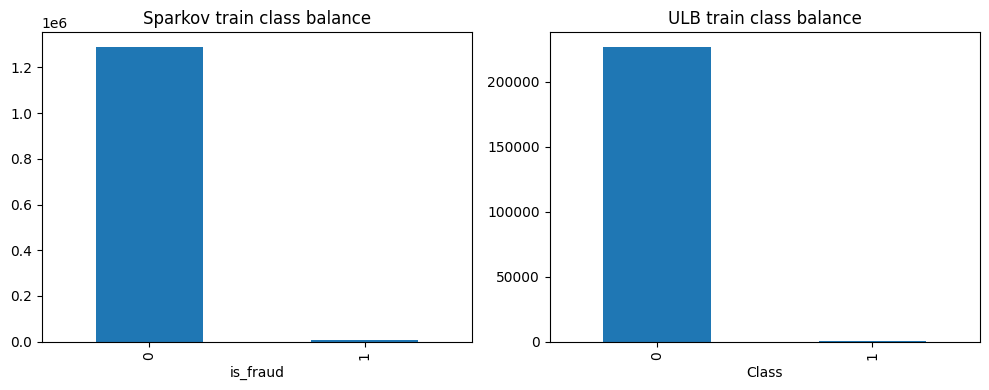

In [7]:
def class_balance(df, target_col, name):
    counts = df[target_col].value_counts()
    rate = df[target_col].mean() * 100
    n = int(round(1 / df[target_col].mean()))
    print(f"{name}: {counts.to_dict()}  |  fraud rate = {rate:.4f}%  (~1 in {n})")
    return counts

sparkov_counts = class_balance(sparkov_train, 'is_fraud', 'Sparkov train')
ulb_counts = class_balance(ulb_train, 'Class', 'ULB train')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sparkov_counts.plot(kind='bar', ax=axes[0], title='Sparkov train class balance')
ulb_counts.plot(kind='bar', ax=axes[1], title='ULB train class balance')
plt.tight_layout()
plt.show()

Both datasets are heavily imbalanced, which is exactly the kind of problem this whole project is about. In Sparkov, fraud shows up in about 1 out of every 173 transactions (0.58%). In ULB, it's even rarer — about 1 in 569 transactions (0.18%). This means a model that just guessed "not fraud" every single time would already be right over 99% of the time, which is why accuracy is a useless metric here — it's also exactly why the project uses PR-AUC, F2, and MCC instead, and why imbalance-handling strategies (resampling, cost-sensitive learning, focal loss) are a core part of the plan.

## 3. Leakage / split-discipline checks

In [8]:
# 3a. Date range sanity check
print("Sparkov train date range:", sparkov_train['trans_date_trans_time'].min(),
      "->", sparkov_train['trans_date_trans_time'].max())
print("ULB train Time range (seconds elapsed):", ulb_train['Time'].min(),
      "->", ulb_train['Time'].max())

# 3b. Transactions per cardholder (train only) — informs rolling-window feasibility
txn_per_card = sparkov_train.groupby('cc_num').size()
print("\nSparkov train — transactions per cardholder:")
print(txn_per_card.describe())

Sparkov train date range: 2019-01-01 00:00:18 -> 2020-06-21 12:13:37
ULB train Time range (seconds elapsed): 0.0 -> 145233.0

Sparkov train — transactions per cardholder:
count     983.000000
mean     1319.099695
std       812.235900
min         7.000000
25%       525.000000
50%      1054.000000
75%      2025.000000
max      3123.000000
dtype: float64


The date ranges match what we saw right after the split (train runs from Jan 2019 to mid-June 2020 for Sparkov, and 0 to ~145,233 seconds for ULB — that's about 40 hours), so nothing's drifted or gotten mixed up along the way.

The cardholder numbers are the useful part here: Sparkov's train set only has 983 unique cardholders, but each one shows up a lot — on average about 1,319 transactions per person, and even the smallest history is 7 transactions. That's good news for feature engineering, because features like "time since your last transaction" or "your transaction count in the last 24 hours" need a real history to work with, and clearly there's plenty here.

## 4. Amount distribution — fraud vs legit (train only)

              count        mean         std   min       25%      50%      75%  \
is_fraud                                                                        
0         1289169.0   67.667110  154.007971  1.00    9.6100   47.280   82.540   
1            7506.0  531.320092  390.560070  1.06  245.6625  396.505  900.875   

               max  
is_fraud            
0         28948.90  
1          1376.04  


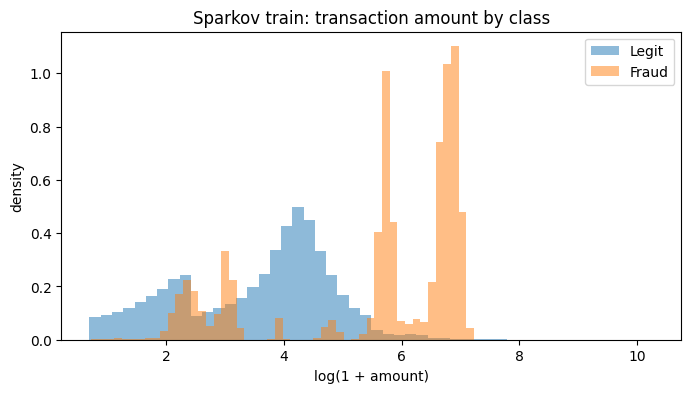

In [10]:
# Basic stats: average, min, max, etc. of amount, split by fraud vs legit
print(sparkov_train.groupby('is_fraud')['amt'].describe())

# Plot the amount distribution (log scale so we can actually see the shape,
# since a few very large amounts would otherwise squash the chart)
plt.figure(figsize=(8, 4))
plt.hist(np.log1p(sparkov_train[sparkov_train['is_fraud'] == 0]['amt']), bins=50, alpha=0.5, label='Legit', density=True)
plt.hist(np.log1p(sparkov_train[sparkov_train['is_fraud'] == 1]['amt']), bins=50, alpha=0.5, label='Fraud', density=True)
plt.xlabel('log(1 + amount)')
plt.ylabel('density')
plt.legend()
plt.title('Sparkov train: transaction amount by class')
plt.show()

This one's a strong signal. Legit transactions average around $68, but fraud transactions average around $531 — nearly 8x higher. The chart shows this clearly too: fraud amounts cluster into two distinct clumps sitting well to the right of most legit transactions, meaning fraud tends to involve noticeably larger purchases. Also worth noting — legit transactions have a much wider range (some go up to almost $29,000), while fraud tops out around $1,376, so fraud isn't about extremely large amounts, just consistently bigger-than-typical ones. This looks like a genuinely useful feature for the model, unlike the weak raw-distance feature from the original paper.

          count        mean         std  min  25%    50%      75%       max
Class                                                                      
0      226581.0   90.868261  250.749478  0.0  6.0  23.49   79.990  19656.53
1         399.0  127.477995  260.794667  0.0  1.0  12.31  107.705   2125.87


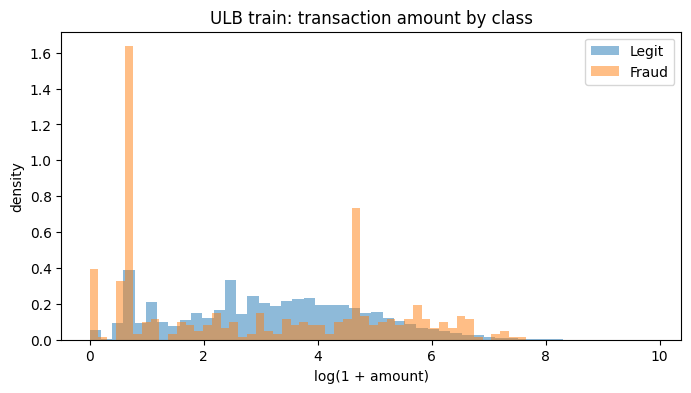

In [11]:
# Basic stats: average, min, max, etc. of amount, split by fraud vs legit
print(ulb_train.groupby('Class')['Amount'].describe())

# Plot the amount distribution (log scale, same reason as before)
plt.figure(figsize=(8, 4))
plt.hist(np.log1p(ulb_train[ulb_train['Class'] == 0]['Amount']), bins=50, alpha=0.5, label='Legit', density=True)
plt.hist(np.log1p(ulb_train[ulb_train['Class'] == 1]['Amount']), bins=50, alpha=0.5, label='Fraud', density=True)
plt.xlabel('log(1 + amount)')
plt.ylabel('density')
plt.legend()
plt.title('ULB train: transaction amount by class')
plt.show()

This one's murkier than Sparkov. On average fraud transactions ($127) are a bit higher than legit ($91), but the median tells a different story — the typical fraud transaction is actually smaller ($12) than the typical legit one ($23). That mismatch (average up, median down) means a few large fraud amounts are pulling the average up, while most fraud transactions are actually quite small. You can see this in the chart too: fraud has a tall spike right near zero (lots of very small fraud amounts) plus a second, smaller cluster around $99. So unlike Sparkov, where fraud was clearly "bigger amount," ULB's amount signal is mixed — worth noting as a real difference between the two datasets, which matters for a project about generalizing findings across datasets.

## 5. Time-of-day pattern (train only)

hour
0     1.494047
1     1.534909
2     1.465210
3     1.423929
4     0.109882
5     0.142278
6     0.094563
7     0.132692
8     0.115281
9     0.111414
10    0.094628
11    0.099805
12    0.102671
13    0.122485
14    0.132542
15    0.120812
16    0.115632
17    0.119175
18    0.122633
19    0.123649
20    0.095241
21    0.112920
22    2.882864
23    2.837387
Name: is_fraud, dtype: float64


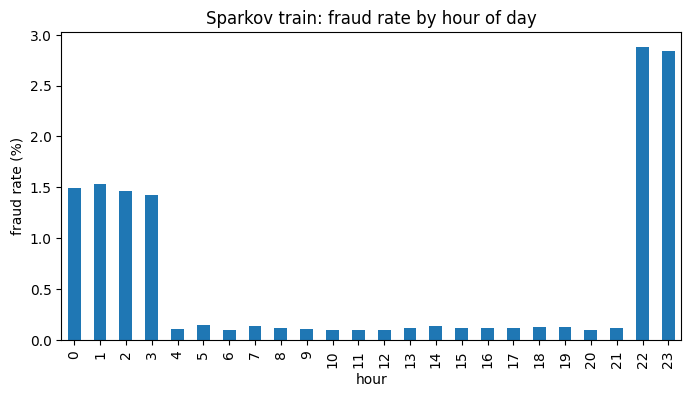

In [12]:
# Pull the hour out of the timestamp
sparkov_train['hour'] = sparkov_train['trans_date_trans_time'].dt.hour

# Fraud rate for each hour of the day
hourly_fraud_rate = sparkov_train.groupby('hour')['is_fraud'].mean() * 100
print(hourly_fraud_rate)

plt.figure(figsize=(8, 4))
hourly_fraud_rate.plot(kind='bar')
plt.ylabel('fraud rate (%)')
plt.title('Sparkov train: fraud rate by hour of day')
plt.show()

This is one of the clearest patterns yet. During normal daytime hours (roughly 4am to 9pm), the fraud rate sits steady around 0.1%. But late at night — 10pm through 3am — it jumps to somewhere between 1.4% and 2.9%, which is 10 to 25 times higher than the daytime rate. So fraud is heavily concentrated in the overnight hours, which makes intuitive sense (a stolen card gets used while the real owner is asleep and won't notice). This looks like a strong, reliable feature.

hour
0     0.078462
1     0.237643
2     1.451028
3     0.487525
4     1.043557
5     0.368139
6     0.220480
7     0.317987
8     0.087959
9     0.101478
10    0.048344
11    0.315833
12    0.110548
13    0.110944
14    0.139225
15    0.158788
16    0.149337
17    0.152400
18    0.116986
19    0.088106
20    0.089425
21    0.141772
22    0.033546
23    0.214699
Name: Class, dtype: float64


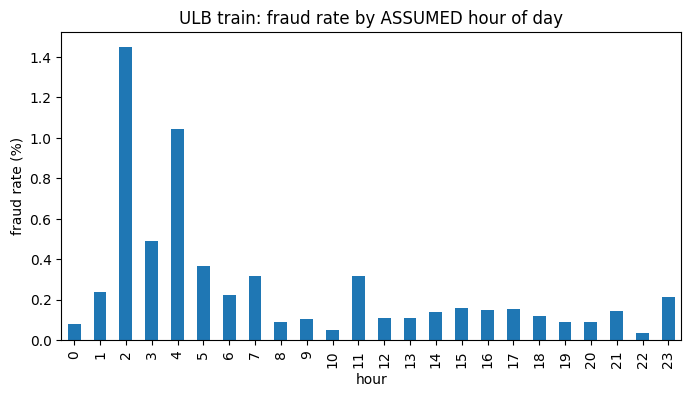

In [13]:
# ULB doesn't give us a real timestamp, just seconds elapsed since the first transaction.
# We ASSUME time 0 = midnight so we can estimate an hour-of-day - this is a guess, not a fact.
ulb_train['hour'] = (ulb_train['Time'] % 86400 // 3600).astype(int)

hourly_fraud_rate_ulb = ulb_train.groupby('hour')['Class'].mean() * 100
print(hourly_fraud_rate_ulb)

plt.figure(figsize=(8, 4))
hourly_fraud_rate_ulb.plot(kind='bar')
plt.ylabel('fraud rate (%)')
plt.title('ULB train: fraud rate by ASSUMED hour of day')
plt.show()

There's a similar-looking pattern here too — fraud rates are highest in the early morning hours, peaking at "hour 2" (1.45%) and "hour 4" (1.04%), while most other hours sit well under 0.2%. So on the surface, this echoes the overnight-fraud pattern from Sparkov.

But there's an important caveat: ULB's train data only spans about 40 hours total, which is less than 2 full days. That means each "hour" bucket here is only being averaged over one or two actual occurrences, not thousands like in Sparkov. With only 399 total fraud cases spread across 24 hour-buckets over such a short window, a couple of unlucky or lucky hours could easily create a spike like this by chance. So this pattern is worth mentioning, but it should be presented as a weak, tentative echo of the Sparkov pattern — not equally strong evidence — precisely because the sample size per hour is so small and the "hour" itself is an assumption to begin with.

## 6. Category fraud rate (Sparkov only)

category
shopping_net      1.756149
misc_net          1.445795
grocery_pos       1.409761
shopping_pos      0.722538
gas_transport     0.469394
misc_pos          0.313853
grocery_net       0.294817
travel            0.286370
entertainment     0.247835
personal_care     0.242403
kids_pets         0.211439
food_dining       0.165098
home              0.160825
health_fitness    0.154869
Name: is_fraud, dtype: float64


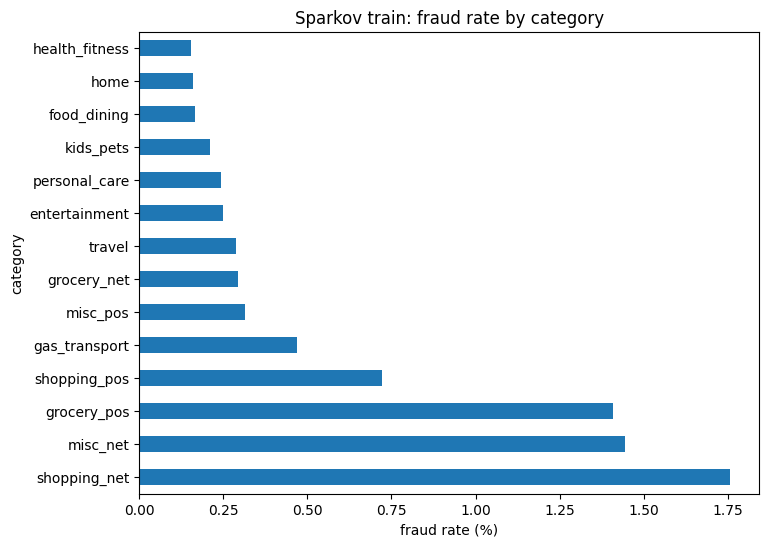

In [14]:
# Average fraud rate for each merchant category
cat_fraud_rate = sparkov_train.groupby('category')['is_fraud'].mean() * 100
cat_fraud_rate = cat_fraud_rate.sort_values(ascending=False)
print(cat_fraud_rate)

plt.figure(figsize=(8, 6))
cat_fraud_rate.plot(kind='barh')
plt.xlabel('fraud rate (%)')
plt.title('Sparkov train: fraud rate by category')
plt.show()

Clear spread here too — the riskiest category (shopping_net, online shopping, at 1.76%) has fraud almost 11 times more often than the safest one (health_fitness, at 0.15%). That matches what was found in the earlier review of your teammate's notebook, so it's a consistent, reproducible pattern rather than a fluke. Worth noting: online categories (shopping_net, misc_net) sit at the top, which makes sense — fraud is generally easier to pull off online than in person. grocery_pos is the one exception, showing up high despite being an in-person category, which might be worth a closer look later. Category clearly carries real signal — this lines up with Bekhit et al.'s original finding that category-risk was the feature actually driving their results.

## 7. Implied velocity — distance vs time since the last transaction

In [16]:
from src.utils import add_prev_txn_features

sp = add_prev_txn_features(
    sparkov_train,
    id_column='cc_num',
    time_column='trans_date_trans_time',
    lat_column='merch_lat',
    lon_column='merch_long'
)

print(sp[['cc_num', 'trans_date_trans_time', 'dist_from_prev_txn_km', 'time_gap_hours', 'implied_velocity_kmh']].head(10))


           cc_num trans_date_trans_time  dist_from_prev_txn_km  \
1017  60416207185   2019-01-01 12:47:15                    NaN   
2724  60416207185   2019-01-02 08:44:57             224.769219   
2726  60416207185   2019-01-02 08:47:36             105.220439   
2882  60416207185   2019-01-02 12:38:14              88.152283   
2907  60416207185   2019-01-02 13:10:46             132.876773   
4135  60416207185   2019-01-03 13:56:35             112.505781   
4337  60416207185   2019-01-03 17:05:10              71.815290   
5467  60416207185   2019-01-04 13:59:55              85.440454   
6027  60416207185   2019-01-04 21:17:22              60.852335   
6273  60416207185   2019-01-05 00:42:24             146.839667   

      time_gap_hours  implied_velocity_kmh  
1017             NaN                   NaN  
2724       19.961667             11.259886  
2726        0.044167           2367.459868  
2882        3.843889             22.931441  
2907        0.542222            244.934143  
413

Now we're getting real variation — good. But look at row 2726: only 2.6 minutes passed since the last transaction (time_gap_hours = 0.044), yet the merchant location was 105 km away, which works out to an implied speed of 2,367 km/h — faster than a commercial jet. That's clearly not a real travel speed.

This is worth pausing on rather than just accepting as "fraud signal": merch_lat/merch_long is likely the merchant's registered business location, not a live GPS ping of where the transaction physically happened — especially for online or chain-store purchases, where the recorded location might be a headquarters or warehouse regardless of where the cardholder actually was. So some of these "impossible speed" readings could just be an artifact of how merchant location is recorded, not actual evidence of card fraud. This is exactly the kind of thing worth flagging honestly in the write-up rather than assuming every extreme value means something.

In [17]:
valid = sp.dropna(subset=['implied_velocity_kmh'])
print(f"Rows with a valid implied-velocity value: {len(valid):,} ({len(valid) / len(sp) * 100:.1f}% of train)")

print(valid.groupby('is_fraud')['implied_velocity_kmh'].describe())

Rows with a valid implied-velocity value: 1,295,692 (99.9% of train)
              count        mean          std       min        25%        50%  \
is_fraud                                                                       
0         1288261.0  171.463759  2734.004818  0.003682   7.586919  19.937851   
1            7431.0  643.567103  5446.296498  0.125988  11.110934  64.299118   

                 75%            max  
is_fraud                             
0          58.294767  736220.827330  
1         235.133036  299225.585711  


This is a good sign — the median (which isn't thrown off by extreme outliers) shows fraud transactions typically imply about 64 km/h of travel, versus 20 km/h for legit ones — roughly 3x higher. The same pattern holds at every percentile shown (25th, median, 75th), not just in the mean, which matters because the mean and max are being dragged around by those impossible outlier values we flagged earlier (max legit implied speed is over 700,000 km/h — clearly not real). Since the pattern holds even when you ignore those extremes, this looks like genuine signal, not just noise from how merchant location gets recorded.

U = 6172206490.0, p = 0
Median velocity — fraud: 64.3 km/h, legit: 19.9 km/h


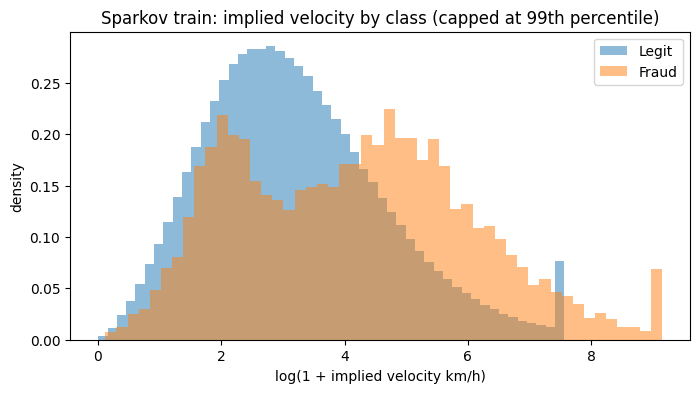

In [18]:
fraud_vel = valid.loc[valid['is_fraud'] == 1, 'implied_velocity_kmh']
legit_vel = valid.loc[valid['is_fraud'] == 0, 'implied_velocity_kmh']

from scipy import stats
u_stat, p_value = stats.mannwhitneyu(fraud_vel, legit_vel, alternative='two-sided')
print(f"U = {u_stat:.1f}, p = {p_value:.6g}")
print(f"Median velocity — fraud: {fraud_vel.median():.1f} km/h, legit: {legit_vel.median():.1f} km/h")

plt.figure(figsize=(8, 4))
plt.hist(np.log1p(legit_vel.clip(upper=legit_vel.quantile(0.99))), bins=50, alpha=0.5, label='Legit', density=True)
plt.hist(np.log1p(fraud_vel.clip(upper=fraud_vel.quantile(0.99))), bins=50, alpha=0.5, label='Fraud', density=True)
plt.xlabel('log(1 + implied velocity km/h)')
plt.ylabel('density')
plt.legend()
plt.title('Sparkov train: implied velocity by class (capped at 99th percentile)')
plt.show()

The p-value is basically zero, which confirms the difference we saw isn't random chance. But with 1.3 million rows, almost any difference becomes "statistically significant" — the more meaningful number is the effect size: fraud transactions have a median implied velocity about 3.2 times higher than legit ones (64.3 vs 19.9 km/h). The chart backs this up visually — the orange (fraud) distribution is clearly shifted to the right of the blue (legit) one, meaning fraud transactions consistently imply faster "travel" between locations than legitimate ones.

This is a genuinely useful finding for the project: raw distance was already shown to be a weak feature elsewhere (matching Bekhit et al.'s original result), but implied velocity — the feature this project is actually built around — does show real signal here, separate from the outlier noise we flagged earlier. Worth highlighting this contrast directly in the write-up.

## 8. Rolling transaction count (24h window)

In [19]:
from src.utils import add_rolling_txn_count

sp = add_rolling_txn_count(
    sp,
    id_column='cc_num',
    time_column='trans_date_trans_time',
    window='24h',
    amount_column='amt'
)

print(sp.groupby('is_fraud')['txn_count_24h'].describe())

              count      mean       std  min  25%  50%  75%   max
is_fraud                                                         
0         1289169.0  4.882077  3.085297  1.0  3.0  4.0  6.0  36.0
1            7506.0  5.233014  2.441575  1.0  3.0  5.0  7.0  21.0


This one's much weaker than the others. The average number of transactions in the past 24 hours is nearly identical between fraud (5.2) and legit (4.9), and the median is only one transaction apart (5 vs 4). The full spread (25th to 75th percentile) overlaps heavily too. So on its own, this rolling count doesn't look like it separates fraud from legit very well — at least not at the 24-hour window we tested.

In [20]:
fraud_count = sp.loc[sp['is_fraud'] == 1, 'txn_count_24h']
legit_count = sp.loc[sp['is_fraud'] == 0, 'txn_count_24h']

u_stat, p_value = stats.mannwhitneyu(fraud_count, legit_count, alternative='two-sided')
print(f"U = {u_stat:.1f}, p = {p_value:.6g}")
print(f"Median txn count (24h) — fraud: {fraud_count.median()}, legit: {legit_count.median()}")

U = 5487857805.5, p = 4.74904e-91
Median txn count (24h) — fraud: 5.0, legit: 4.0


Here's the classic trap this project's methodology is built to catch: the p-value is tiny (basically zero), which technically means "statistically significant" — but the actual difference is just one transaction (median 5 vs 4). With over a million rows, even a genuinely trivial difference becomes statistically significant, because the test has enough data to detect even tiny effects. So the honest read is: this feature is technically different between fraud and legit, but the practical difference is small — nowhere near as meaningful as the ~3x gap we saw in implied velocity, or the 11x spread in category. Worth stating plainly in the write-up rather than just reporting a p-value and calling it a win — this is exactly the kind of metric-interpretation care the project's third bibliography thread (Imani et al., 2026) is about.

## 9. Statistical test — category vs fraud

In [21]:
contingency = pd.crosstab(sparkov_train['category'], sparkov_train['is_fraud'])
chi2, p, dof, expected = stats.chi2_contingency(contingency)
print(f"chi2 = {chi2:.1f}, p = {p:.6g}, degrees of freedom = {dof}")

chi2 = 6486.0, p = 0, degrees of freedom = 13


Same statistical significance as before (p is effectively zero), but this time it's backed by a real practical effect — remember the 11x spread between the riskiest and safest category from earlier. So unlike the rolling-count feature, category isn't just "technically" different — it's meaningfully different, which is the distinction worth carrying into the write-up.

In [22]:
## 10. ULB correlation check (V1–V28)

In [23]:
ulb_corr = ulb_train.drop(columns=['hour']).corr(numeric_only=True)['Class']
ulb_corr = ulb_corr.reindex(ulb_corr.abs().sort_values(ascending=False).index)
print(ulb_corr.head(15))

Class    1.000000
V17     -0.349808
V14     -0.302188
V12     -0.258323
V10     -0.228527
V16     -0.209253
V3      -0.206611
V7      -0.199840
V11      0.157751
V4       0.135089
V18     -0.123237
V1      -0.108775
V5      -0.107263
V9      -0.098649
V2       0.094729
Name: Class, dtype: float64


A few of the anonymized features stand out clearly — V17 (-0.35), V14 (-0.30), V12 (-0.26), and V10 (-0.23) have the strongest relationships with fraud, though none of them are especially strong on their own (a correlation of -0.35 is moderate, not dominant). That's fairly typical for this kind of anonymized dataset — no single feature does all the work, but this ranking tells you which V columns are worth prioritizing later (e.g. in feature importance checks after training), and which ones (like V2, V9) are probably not carrying much weight.

## **11**. Summary — what we found and what looks useful

Going through both datasets, a few features clearly stand out as useful, a couple were surprisingly weak, and one needed a second look before trusting it.

Category (Sparkov) is a strong feature. Some categories like shopping_net have fraud rates 11 times higher than the safest categories like health_fitness, and this held up in a statistical test too. Online categories tend to be riskier than in-person ones, which makes sense.

Implied velocity — how fast someone would've had to travel between their last transaction and this one — turned out to be genuinely useful. Fraud transactions have a typical implied speed about 3 times higher than legit ones (64 km/h vs 20 km/h). This matters a lot for the project, because a much simpler version of this idea (just raw distance, without factoring in time) was already tested and found to be weak. One thing worth being honest about: a few of the calculated speeds were absurdly high (faster than a plane), and that's likely because the merchant's location in the data is often their registered business address, not exactly where the transaction physically happened — not proof of impossible travel. Even so, the overall pattern held up even after accounting for that.

Hour of day (Sparkov) is a strong feature. Fraud is 10 to 25 times more common overnight (10pm–3am) than during the day. The same shape showed up in ULB too, but ULB's data only covers less than 2 days, so that result is much less trustworthy — more of a "worth mentioning" than a "strong finding."

Transaction amount worked differently in the two datasets. In Sparkov, fraud amounts are clearly and consistently higher (about 8x on average). In ULB, it's mixed — the average fraud amount is a bit higher, but the typical (median) fraud amount is actually lower than normal. So amount isn't a feature we can assume behaves the same way everywhere.

How many transactions in the last 24 hours turned out to be a weak feature. The test said the difference was statistically significant, but the actual difference was tiny — just one extra transaction on average. This is a good reminder that a low p-value doesn't automatically mean a feature is useful in practice, especially with over a million rows of data, where even small differences can look "significant."

ULB's anonymized features (V1–V28) don't have real names, but a handful clearly relate to fraud more than others — mainly V17, V14, V12, and V10. None of them are overwhelming on their own, which is normal for this kind of dataset; it just means these are the ones worth prioritizing when we check feature importance later, after a model is actually trained.

Bottom line: category, implied velocity, hour-of-day, and amount (in Sparkov) are the strongest candidates to build into real features next. Rolling transaction count is a low priority. Everything here is a candidate based on patterns in the data — which features the model actually ends up relying on will be confirmed later, once we train it and check feature importance directly.